# RQ1 results: Phase 1 and Phase 2

Computes every RQ1 number from the coded files, so the results don't depend on summaries written by hand
or by Claude. Run top to bottom. Each section saves its tables to `results/rq1/` (CSV) and figures to
`results/rq1/figs/` (PNG), so the paper can cite one place.

Inputs (read only):
- `open_coding/themes.md`: frozen codebook (open code -> subtheme -> theme)
- `open_coding/open_codes.csv`: Phase 1 key points
- `coding_rounds/phase1_round*_key.csv`: Phase 1 labels (joined here, after coding)
- `phase2_coding/phase2_codes.csv`, `coding_rounds/phase2_key.csv`: Phase 2 key points and labels
- `phase2_coding/phase2_spotcheck.csv`: human spot-check verdicts (optional)

Counting rules (same as the coding): a pair counts **once** for a theme or subtheme if any of its key points
has it. Pairs with no author change or no diff are excluded from change tables and reported separately.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

ROOT = Path(".")
CODING_DIR = ROOT / "coding_rounds"
OPEN_DIR = ROOT / "open_coding"
P2_DIR = ROOT / "phase2_coding"
OUT = ROOT / "results" / "rq1"
FIGS = OUT / "figs"
FIGS.mkdir(parents=True, exist_ok=True)

STRATA = ["introduced", "fixed", "no change"]
BASELINE = "no change"       # comparison group for the association tests
ALPHA = 0.05

# Stratum pool sizes at the Phase 2 draw (rq1_sampling.ipynb, Phase 2 plan cell output).
# Used only to weight Phase 2 back to the population.
POOL_N = {"fixed": 10645, "introduced": 14233, "no change": 67816}

NO_CHANGE_CODES = {"no author change", "no change"}
UNAVAILABLE_CODES = {"diff unavailable"}

pd.set_option("display.max_rows", 200, "display.max_colwidth", 80)


def save(df, name, index=True, fmt=None):
    """Save a table to results/rq1/<name>.csv and show it (formatted if fmt is given)."""
    df.to_csv(OUT / f"{name}.csv", index=index, encoding="utf-8-sig")
    display(df.style.format(fmt, na_rep="-") if fmt else df)


def load_codebook(path=OPEN_DIR / "themes.md"):
    """open code -> (subtheme, theme), parsed from the 'Open codes (pairs):' lines of themes.md."""
    theme = sub = None
    rows = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("## Theme: "):
            theme = line[len("## Theme: "):].strip()
        elif line.startswith("### Subtheme: "):
            sub = line[len("### Subtheme: "):].strip()
        elif line.startswith("- Open codes (pairs):") and sub:
            for item in line.split(":", 1)[1].split(";"):
                c = re.sub(r"\s*\(\d+\)\s*$", "", item.strip())
                if c:
                    rows.append({"open_code": c, "subtheme": sub, "theme": theme})
    cb = pd.DataFrame(rows)
    assert cb["open_code"].is_unique, "an open code is listed under two subthemes in themes.md"
    return cb


def wilson(k, n, z=1.96):
    """95% Wilson interval for k/n, returned as (low, high)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0, c - h), min(1, c + h))


def bh(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p, float)
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum() == 0:
        return q
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(pv)
    out[order] = np.minimum(ranked, 1)
    q[ok] = out
    return q


def pair_presence(kp, col):
    """Pair x category 0/1 matrix: 1 if any key point of the pair has that category."""
    return pd.crosstab(kp["pair_id"], kp[col]).clip(upper=1)


def shares_with_ci(presence, pair_stratum, strata=STRATA):
    """Long table: category, stratum, pairs, n, share, ci_low, ci_high."""
    rows = []
    strat = pair_stratum.reindex(presence.index)
    for s in strata + ["all"]:
        mask = np.ones(len(presence), bool) if s == "all" else (strat == s).values
        n = int(mask.sum())
        for cat in presence.columns:
            k = int(presence.loc[mask, cat].sum())
            lo, hi = wilson(k, n)
            rows.append({"category": cat, "stratum": s, "pairs": k, "n": n,
                         "share": k / n if n else np.nan, "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


def wide_share(long, value="share"):
    t = long.pivot(index="category", columns="stratum", values=value)
    return t[[c for c in STRATA + ["all"] if c in t.columns]]


# stated_motive groups from themes.md (same keyword lists as the join cell in rq1_sampling.ipynb).
# Each key point gets the first group whose keywords it matches (same rule as themes.md, which this
# reproduces exactly). A pair can still be in several groups through different key points.
MOTIVE_GROUPS = [
    ("Respond to registry scanner or audit findings (incl. reducing false positives)",
     ["security-audit", "security-scan", "security warnings", "ClawScan", "suspicious", "false-positive",
      "false positive", "SkillSpector", "Registry Mismatch", "security concern", "ClawHub feedback",
      "security wording", "triggered security scanner", "sensitive path warnings", "trust cleanup"]),
    ("Security hardening / prevent harm",
     ["security", "hardening", "hardened", "exfiltration", "injection", "disclose local files", "plaintext token",
      "never hardcoded", "propagation", "pre-created by another user", "no longer stored on disk",
      "accidental execution", "risk-reducing", "Chrome windows"]),
    ("Fix a defect or improve reliability/compatibility/performance",
     ["import failure", "torn JSON", "recovers", "understated", "--live", "UnicodeEncodeError", "already sent",
      "stale", "never surfaced", "ABI", "silently skipped", "403s", "unnecessary API calls",
      "slow URL validation", "reliability", "compatibility", "survive skill upgrades"]),
    ("Registry or metadata compatibility",
     ["registry parses", "align metadata", "unsupported skill frontmatter", "registry/install",
      "match real requirements"]),
    ("Simplify setup or usage",
     ["cleaner setup", "simplify configuration", "simplifying", "simpler setup", "lightweight", "brevity"]),
    ("Consistency of formatting", ["consistency"]),
    ("Accurate or honest description", ["honest", "duplicate premium", "credential handling contradiction"]),
    ("Discoverability and traffic tracking", ["discoverability", "traffic source", "UTM truncation"]),
    ("Product or business structure", ["paid features", "canonical maintained", "external wallet"]),
]


def motive_group(text):
    t = str(text).lower()
    for name, words in MOTIVE_GROUPS:
        if any(w.lower() in t for w in words):
            return name
    return "other"


def motive_long(kp):
    """One row per (pair, motive group) for key points that state a motive."""
    m = kp[kp["stated_motive"].str.strip() != ""][["pair_id", "stated_motive"]].copy()
    m["motive_group"] = m["stated_motive"].map(motive_group)
    return m[["pair_id", "motive_group"]].drop_duplicates()


codebook = load_codebook()
SUB2THEME = dict(zip(codebook["subtheme"], codebook["theme"]))
CHANGE_SUBTHEMES = [s for s in codebook["subtheme"].unique() if s != "No change"]
print(f"codebook: {len(codebook)} open codes, {len(CHANGE_SUBTHEMES)} change subthemes, "
      f"{codebook.loc[codebook.subtheme != 'No change', 'theme'].nunique()} change themes")

codebook: 144 open codes, 16 change subthemes, 7 change themes


## Phase 1: open coding rounds (codebook development)

Phase 1 rounds were drawn **balanced** across strata (about 17/17/16 per round) to build the codebook.
Its shares describe the coded pairs, not the ClawHub population. Population claims come from Phase 2.

In [2]:
p1 = pd.read_csv(OPEN_DIR / "open_codes.csv", dtype=str).fillna("")
p1 = p1.merge(codebook, on="open_code", how="left")
unmapped = sorted(p1.loc[p1["subtheme"].isna(), "open_code"].unique())
if unmapped:
    print("WARNING: open codes not in themes.md:", unmapped)

p1_rounds = sorted(p1["round"].unique())

# pair-level flags
p1_pairs = p1.groupby("pair_id").agg(round=("round", "first"),
                                     changelog_mismatch=("changelog_mismatch", "first"),
                                     no_author_change=("no_author_change", "first")).reset_index()
unavailable = set(p1.loc[p1["open_code"].isin(UNAVAILABLE_CODES), "pair_id"])
p1_pairs["excluded"] = ""
p1_pairs.loc[p1_pairs["no_author_change"] == "yes", "excluded"] = "no author change"
p1_pairs.loc[p1_pairs["pair_id"].isin(unavailable), "excluded"] = "diff unavailable"

# labels: join the Phase 1 key files (only now, after coding)
key_files = sorted(CODING_DIR.glob("phase1_round*_key.csv"))
if key_files:
    p1_key = pd.concat(pd.read_csv(f, dtype=str) for f in key_files)[["pair_id", "stratum"]]
    p1_pairs = p1_pairs.merge(p1_key.drop_duplicates("pair_id"), on="pair_id", how="left")
    if p1_pairs["stratum"].isna().any():
        print(f"WARNING: {p1_pairs['stratum'].isna().sum()} Phase 1 pairs have no key row")
else:
    p1_pairs["stratum"] = np.nan
    print("no Phase 1 key files found: stratum tables will be skipped")

p1_inc = p1_pairs[p1_pairs["excluded"] == ""]
p1_kp = p1[p1["pair_id"].isin(p1_inc["pair_id"])]
print(f"Phase 1: {p1_pairs.shape[0]} pairs, {len(p1)} key points, {p1['open_code'].nunique()} open codes")
print(f"excluded: {(p1_pairs.excluded == 'no author change').sum()} no author change, "
      f"{(p1_pairs.excluded == 'diff unavailable').sum()} diff unavailable; "
      f"{len(p1_inc)} pairs with changes, {len(p1_kp)} key points")

Phase 1: 400 pairs, 862 key points, 144 open codes
excluded: 48 no author change, 5 diff unavailable; 347 pairs with changes, 809 key points


### 1a. Saturation (recomputed from `open_codes.csv`)

`new codes` = codes first applied in that round (after the consistency sweep), so it should match the
"new open codes" column of `saturation_log.md`. `new subthemes` uses the **final** codebook, so it can differ
from the log, which recorded the provisional grouping at the time of each round. Report the log's column for
subthemes and this table for codes.

,pairs,key_points,new_codes,codes_so_far,new_codes_pct,new_subthemes_final_codebook,no_author_change,meets_rule
round,,,,,,,,
phase1_round01,50,115,79,79,100.0%,15,6,False
phase1_round02,50,107,30,109,27.5%,1,2,False
phase1_round03,50,97,15,124,12.1%,0,8,False
phase1_round04,50,102,10,134,7.5%,0,7,False
phase1_round05,50,112,4,138,2.9%,0,4,True
phase1_round06,50,104,1,139,0.7%,0,10,True
phase1_round07,50,108,2,141,1.4%,0,7,True
phase1_round08,50,117,3,144,2.1%,0,4,True


saturation reached at: phase1_round06


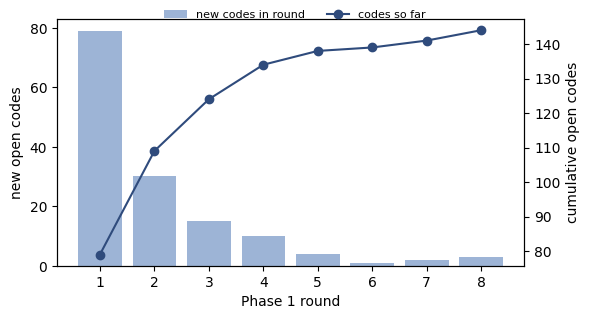

In [3]:
first_code = p1.sort_values("round").groupby("open_code")["round"].first()
first_sub = p1[p1["subtheme"] != "No change"].sort_values("round").groupby("subtheme")["round"].first()

rows, seen = [], 0
for r in p1_rounds:
    d = p1[p1["round"] == r]
    new = int((first_code == r).sum())
    seen += new
    rows.append({"round": r, "pairs": d["pair_id"].nunique(), "key_points": len(d),
                 "new_codes": new, "codes_so_far": seen, "new_codes_pct": new / seen,
                 "new_subthemes_final_codebook": int((first_sub == r).sum()),
                 "no_author_change": int((p1_pairs[p1_pairs["round"] == r]["no_author_change"] == "yes").sum())})
sat = pd.DataFrame(rows).set_index("round")

# saturation rule: 2 rounds in a row, from round 4, with no new subthemes and new codes under 5%
ok = (sat["new_subthemes_final_codebook"] == 0) & (sat["new_codes_pct"] < 0.05)
ok.iloc[:3] = False
sat["meets_rule"] = ok
hit = [sat.index[i] for i in range(1, len(sat)) if ok.iloc[i] and ok.iloc[i - 1]]
save(sat, "p1_saturation", fmt={"new_codes_pct": "{:.1%}"})
print("saturation reached at:", hit[0] if hit else "not reached")

fig, ax = plt.subplots(figsize=(6, 3.2))
x = range(1, len(sat) + 1)
ax.bar(x, sat["new_codes"], color="#9db4d6", label="new codes in round")
ax2 = ax.twinx()
ax2.plot(x, sat["codes_so_far"], "o-", color="#2f4b7c", label="codes so far")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Phase 1 round"); ax.set_ylabel("new open codes"); ax2.set_ylabel("cumulative open codes")
ax.set_xticks(list(x))
fig.legend(loc="upper center", ncol=2, frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "p1_saturation.png", dpi=200); plt.show()

### 1b. Themes and subthemes (pairs with changes)

In [4]:
n1 = len(p1_inc)
sub_pairs = pair_presence(p1_kp, "subtheme").sum().rename("pairs")
theme_pairs = pair_presence(p1_kp, "theme").sum().rename("pairs")

t = theme_pairs.to_frame()
t["share"] = t["pairs"] / n1
t["key_points"] = p1_kp.groupby("theme").size()
t = t.sort_values("pairs", ascending=False)
print(f"themes, share of {n1} Phase 1 pairs with changes:")
save(t, "p1_themes")

s = sub_pairs.to_frame()
s["theme"] = s.index.map(SUB2THEME)
s["share"] = s["pairs"] / n1
s["key_points"] = p1_kp.groupby("subtheme").size()
s = s.sort_values(["theme", "pairs"], ascending=[True, False])
save(s, "p1_subthemes")

# per round (pairs), to show the themes are stable across rounds
per_round = pd.crosstab(p1_kp.drop_duplicates(["pair_id", "theme"])["theme"],
                        p1_kp.drop_duplicates(["pair_id", "theme"])["round"])
save(per_round, "p1_themes_per_round")

# direction split (key points)
save(pd.crosstab(p1_kp["theme"], p1_kp["direction"], margins=True, margins_name="total"), "p1_direction_by_theme")

themes, share of 347 Phase 1 pairs with changes:


,pairs,share,key_points
theme,,,
Upkeep and presentation,203,0.585014,246
Configuration and declared requirements,115,0.331412,140
Functional behavior,111,0.319885,153
Safety controls and risk communication,75,0.216138,111
Dependencies and external reach,62,0.178674,71
Package composition,53,0.152738,73
Monetization,14,0.040346,15


,pairs,theme,share,key_points
subtheme,,,,
Metadata declarations,80,Configuration and declared requirements,0.230548,90
Credentials and configuration values,46,Configuration and declared requirements,0.132565,50
Installation and dependencies,39,Dependencies and external reach,0.112392,47
External services and endpoints,23,Dependencies and external reach,0.066282,24
Feature and capability scope,82,Functional behavior,0.236311,98
Code implementation changes,39,Functional behavior,0.112392,55
Payments and monetization,14,Monetization,0.040346,15
Package file housekeeping,43,Package composition,0.123919,60
Testing assets,13,Package composition,0.037464,13


round,phase1_round01,phase1_round02,phase1_round03,phase1_round04,phase1_round05,phase1_round06,phase1_round07,phase1_round08
theme,,,,,,,,
Configuration and declared requirements,11,16,18,13,15,14,14,14
Dependencies and external reach,12,12,5,4,6,8,7,8
Functional behavior,15,15,13,16,10,15,12,15
Monetization,3,2,1,1,1,2,4,0
Package composition,6,9,6,7,8,5,7,5
Safety controls and risk communication,8,7,9,13,10,7,8,13
Upkeep and presentation,25,25,23,19,30,26,25,30


direction,added,modified,removed,total
theme,,,,
Configuration and declared requirements,77,17,46,140
Dependencies and external reach,30,28,13,71
Functional behavior,85,48,20,153
Monetization,10,3,2,15
Package composition,19,17,37,73
Safety controls and risk communication,92,5,14,111
Upkeep and presentation,61,177,8,246
total,374,295,140,809


### 1c. Phase 1 by stratum (descriptive)

Small samples (about 130 pairs per stratum) and drawn balanced, so read these as hints for Phase 2,
not as findings.

In [5]:
if p1_pairs["stratum"].notna().any():
    st1 = p1_inc.set_index("pair_id")["stratum"]
    long1 = shares_with_ci(pair_presence(p1_kp, "theme"), st1)
    print("theme share of pairs within each stratum:")
    save(wide_share(long1), "p1_theme_by_stratum", fmt="{:.1%}")
    long1s = shares_with_ci(pair_presence(p1_kp, "subtheme"), st1)
    save(wide_share(long1s), "p1_subtheme_by_stratum")
    save(pd.crosstab(p1_pairs["changelog_mismatch"], p1_pairs["stratum"], margins=True, margins_name="total"),
         "p1_mismatch_by_stratum")
    save(pd.crosstab(p1_pairs["excluded"].replace("", "has changes"), p1_pairs["stratum"],
                     margins=True, margins_name="total"), "p1_exclusions_by_stratum")
else:
    print("skipped: no Phase 1 key files")

theme share of pairs within each stratum:


stratum,introduced,fixed,no change,all
category,,,,
Configuration and declared requirements,29.7%,38.2%,31.1%,33.1%
Dependencies and external reach,16.9%,18.7%,17.9%,17.9%
Functional behavior,31.4%,32.5%,32.1%,32.0%
Monetization,4.2%,2.4%,5.7%,4.0%
Package composition,15.3%,15.4%,15.1%,15.3%
Safety controls and risk communication,15.3%,30.9%,17.9%,21.6%
Upkeep and presentation,61.9%,54.5%,59.4%,58.5%


stratum,introduced,fixed,no change,all
category,,,,
Agent behavior guardrails,0.059322,0.097561,0.047170,0.069164
Code implementation changes,0.093220,0.130081,0.113208,0.112392
Code-level safety checks,0.025424,0.089431,0.037736,0.051873
Credentials and configuration values,0.110169,0.146341,0.141509,0.132565
Description and naming,0.194915,0.276423,0.188679,0.221902
Documentation content,0.338983,0.276423,0.349057,0.319885
External services and endpoints,0.067797,0.073171,0.056604,0.066282
Feature and capability scope,0.262712,0.211382,0.235849,0.236311
Installation and dependencies,0.101695,0.113821,0.122642,0.112392


stratum,fixed,introduced,no change,total
changelog_mismatch,,,,
generic,21,30,18,69
no,103,87,89,279
yes,12,19,21,52
total,136,136,128,400


stratum,fixed,introduced,no change,total
excluded,,,,
diff unavailable,1,2,2,5
has changes,123,118,106,347
no author change,12,16,20,48
total,136,136,128,400


### 1d. Pair flags and stated motives

In [6]:
save(pd.crosstab(p1_pairs["round"], p1_pairs["changelog_mismatch"], margins=True, margins_name="total"),
     "p1_mismatch_by_round")
mismatch_empty = ((p1_pairs["changelog_mismatch"] == "yes") & (p1_pairs["no_author_change"] == "yes")).sum()
print(f"mismatch = yes with an empty diff: {mismatch_empty} pairs")

m1 = motive_long(p1)
print(f"{m1['pair_id'].nunique()} of {len(p1_pairs)} pairs state a motive (a pair can be in several groups)")
save(m1["motive_group"].value_counts().rename("pairs").to_frame(), "p1_motives")

changelog_mismatch,generic,no,yes,total
round,,,,
phase1_round01,8,34,8,50
phase1_round02,10,36,4,50
phase1_round03,10,34,6,50
phase1_round04,5,40,5,50
phase1_round05,4,37,9,50
phase1_round06,9,32,9,50
phase1_round07,13,33,4,50
phase1_round08,10,33,7,50
total,69,279,52,400


mismatch = yes with an empty diff: 18 pairs
69 of 400 pairs state a motive (a pair can be in several groups)


,pairs
motive_group,
Fix a defect or improve reliability/compatibility/performance,18
Security hardening / prevent harm,18
Respond to registry scanner or audit findings (incl. reducing false positives),17
Simplify setup or usage,6
Registry or metadata compatibility,5
Product or business structure,3
Accurate or honest description,2
Consistency of formatting,2
Discoverability and traffic tracking,2


## Phase 2: measurement sample (frozen codebook)

Stratified sample, 95% confidence and 5% margin of error per stratum. Shares within a stratum are direct
estimates for that stratum. The `all (weighted)` column weights strata back to their population size, which
is the number to use for ClawHub-wide claims.

In [7]:
p2 = pd.read_csv(P2_DIR / "phase2_codes.csv", dtype=str).fillna("")
p2_key = pd.read_csv(CODING_DIR / "phase2_key.csv", dtype=str)[["pair_id", "stratum"]]
p2 = p2.merge(p2_key, on="pair_id", how="left")

# ---- checks before any result ----
problems = []
if p2["stratum"].isna().any():
    problems.append(f"{p2.loc[p2['stratum'].isna(), 'pair_id'].nunique()} coded pairs not in phase2_key.csv")
missing = set(p2_key["pair_id"]) - set(p2["pair_id"])
if missing:
    problems.append(f"{len(missing)} drawn pairs have no codes")
special = {"UNFIT", "no change", "diff unavailable"}
bad_sub = sorted(set(p2["subtheme"]) - set(CHANGE_SUBTHEMES) - special)
if bad_sub:
    problems.append(f"subthemes not in themes.md: {bad_sub}")
wrong_theme = p2[p2["subtheme"].isin(CHANGE_SUBTHEMES) & (p2["theme"] != p2["subtheme"].map(SUB2THEME))]
if len(wrong_theme):
    problems.append(f"{len(wrong_theme)} key points have a theme that doesn't match their subtheme "
                    "(fixed below from the codebook)")
    p2.loc[wrong_theme.index, "theme"] = p2.loc[wrong_theme.index, "subtheme"].map(SUB2THEME)
if "read_mode" not in p2.columns:
    problems.append("no read_mode column: can't separate fully read from partly read pairs")
    p2["read_mode"] = ""
elif (p2["read_mode"].str.strip() == "").any():
    problems.append(f"{p2.loc[p2['read_mode'].str.strip() == '', 'pair_id'].nunique()} pairs have no read_mode")
print("checks:", "all passed" if not problems else "")
for p in problems:
    print("  -", p)

p2_pairs = p2.groupby("pair_id").agg(stratum=("stratum", "first"),
                                     no_author_change=("no_author_change", "first"),
                                     diff_unavailable=("diff_unavailable", "first"),
                                     changelog_mismatch=("changelog_mismatch", "first"),
                                     read_mode=("read_mode", "first")).reset_index()
p2_pairs["excluded"] = ""
p2_pairs.loc[p2_pairs["no_author_change"] == "yes", "excluded"] = "no author change"
p2_pairs.loc[p2_pairs["diff_unavailable"] == "yes", "excluded"] = "diff unavailable"

print(f"\n{p2_pairs.shape[0]:,} of {len(p2_key):,} pairs coded, {len(p2):,} key points")
save(pd.crosstab(p2_pairs["excluded"].replace("", "has changes"), p2_pairs["stratum"],
                 margins=True, margins_name="total"), "p2_exclusions_by_stratum")

p2_inc = p2_pairs[p2_pairs["excluded"] == ""]
p2_kp = p2[p2["pair_id"].isin(p2_inc["pair_id"])]
p2_kp_coded = p2_kp[p2_kp["subtheme"] != "UNFIT"]
st2 = p2_inc.set_index("pair_id")["stratum"]

print("quality flags (pairs with changes):")
q = pd.DataFrame({
    "pairs": p2_inc.groupby("stratum").size(),
    "partly_read": p2_inc[p2_inc["read_mode"] == "partly read"].groupby("stratum").size(),
    "with_UNFIT": p2_kp[p2_kp["subtheme"] == "UNFIT"].drop_duplicates("pair_id").groupby("stratum").size(),
    "with_low_conf": p2_kp[p2_kp["confidence"] == "low"].drop_duplicates("pair_id").groupby("stratum").size(),
}).fillna(0).astype(int)
q.loc["total"] = q.sum()
save(q, "p2_quality_flags")

checks: 
  - 11 pairs have no read_mode

1,300 of 1,300 pairs coded, 2,776 key points


stratum,fixed,introduced,no change,total
excluded,,,,
diff unavailable,6,3,2,11
has changes,388,392,384,1164
no author change,33,37,55,125
total,427,432,441,1300


quality flags (pairs with changes):


,pairs,partly_read,with_UNFIT,with_low_conf
stratum,,,,
fixed,388,4,0,0
introduced,392,7,0,2
no change,384,8,0,1
total,1164,19,0,3


### 2a. Prevalence of themes and subthemes by stratum

`share` = pairs with that theme / pairs with changes in the stratum, with a 95% Wilson interval.
`all (weighted)` weights each stratum by its population size, adjusted for its share of pairs with changes.

In [8]:
# population weights: pool size x share of drawn pairs that had changes
drawn = p2_pairs.groupby("stratum").size()
inc_n = p2_inc.groupby("stratum").size()
pop_changed = pd.Series({s: POOL_N[s] * inc_n.get(s, 0) / drawn.get(s, 1) for s in STRATA})
W = pop_changed / pop_changed.sum()
print("estimated population share of each stratum among pairs with changes:")
display(W.rename("weight").to_frame().style.format("{:.1%}"))


def prevalence(col, name):
    pres = pair_presence(p2_kp_coded, col).reindex(st2.index, fill_value=0)
    long = shares_with_ci(pres, st2)
    w = wide_share(long)
    ci = long.assign(ci=lambda d: d.apply(lambda r: f"{r.share:.1%} [{r.ci_low:.1%}, {r.ci_high:.1%}]", axis=1))
    ci = ci.pivot(index="category", columns="stratum", values="ci")[[s for s in STRATA + ["all"]]]
    w["all (weighted)"] = sum(w[s] * W[s] for s in STRATA)
    ci["all (weighted)"] = w["all (weighted)"].map("{:.1%}".format)
    if col == "subtheme":
        ci.insert(0, "theme", ci.index.map(SUB2THEME))
        w.insert(0, "theme", w.index.map(SUB2THEME))
    ci = ci.loc[w.sort_values("all (weighted)", ascending=False).index]
    long.to_csv(OUT / f"{name}_long.csv", index=False, encoding="utf-8-sig")
    save(ci, name)
    return w, long


theme_w, theme_long = prevalence("theme", "p2_theme_by_stratum")
sub_w, sub_long = prevalence("subtheme", "p2_subtheme_by_stratum")

estimated population share of each stratum among pairs with changes:


,weight
introduced,15.8%
fixed,11.8%
no change,72.3%


stratum,introduced,fixed,no change,all,all (weighted)
category,,,,,
Upkeep and presentation,"53.1% [48.1%, 57.9%]","43.6% [38.7%, 48.5%]","57.8% [52.8%, 62.7%]","51.5% [48.6%, 54.3%]",55.4%
Functional behavior,"41.1% [36.3%, 46.0%]","25.0% [21.0%, 29.5%]","35.7% [31.0%, 40.6%]","33.9% [31.3%, 36.7%]",35.3%
Safety controls and risk communication,"32.7% [28.2%, 37.4%]","38.7% [33.9%, 43.6%]","33.6% [29.1%, 38.5%]","35.0% [32.3%, 37.8%]",34.0%
Configuration and declared requirements,"24.5% [20.5%, 29.0%]","40.7% [35.9%, 45.7%]","22.1% [18.3%, 26.6%]","29.1% [26.6%, 31.8%]",24.7%
Dependencies and external reach,"25.3% [21.2%, 29.8%]","18.3% [14.8%, 22.5%]","16.1% [12.8%, 20.2%]","19.9% [17.7%, 22.3%]",17.8%
Package composition,"12.8% [9.8%, 16.4%]","9.5% [7.0%, 12.9%]","12.2% [9.3%, 15.9%]","11.5% [9.8%, 13.5%]",12.0%
Monetization,"3.6% [2.1%, 5.9%]","3.9% [2.4%, 6.3%]","4.9% [3.2%, 7.6%]","4.1% [3.1%, 5.4%]",4.6%


stratum,theme,introduced,fixed,no change,all,all (weighted)
category,,,,,,
Documentation content,Upkeep and presentation,"29.1% [24.8%, 33.8%]","24.5% [20.5%, 29.0%]","38.5% [33.8%, 43.5%]","30.7% [28.1%, 33.4%]",35.4%
Feature and capability scope,Functional behavior,"32.9% [28.4%, 37.7%]","20.4% [16.7%, 24.6%]","29.9% [25.6%, 34.7%]","27.7% [25.3%, 30.4%]",29.3%
Release status and bookkeeping,Upkeep and presentation,"15.8% [12.5%, 19.8%]","16.2% [12.9%, 20.2%]","18.8% [15.2%, 23.0%]","16.9% [14.9%, 19.2%]",18.0%
Agent behavior guardrails,Safety controls and risk communication,"17.9% [14.4%, 22.0%]","17.0% [13.6%, 21.1%]","18.0% [14.5%, 22.1%]","17.6% [15.5%, 19.9%]",17.8%
Metadata declarations,Configuration and declared requirements,"14.8% [11.6%, 18.7%]","30.2% [25.8%, 34.9%]","13.8% [10.7%, 17.6%]","19.6% [17.4%, 22.0%]",15.9%
Description and naming,Upkeep and presentation,"15.8% [12.5%, 19.8%]","11.6% [8.8%, 15.2%]","12.5% [9.6%, 16.2%]","13.3% [11.5%, 15.4%]",12.9%
Safety and transparency guidance,Safety controls and risk communication,"9.7% [7.1%, 13.0%]","15.2% [12.0%, 19.1%]","11.7% [8.9%, 15.3%]","12.2% [10.4%, 14.2%]",11.8%
Installation and dependencies,Dependencies and external reach,"16.8% [13.5%, 20.9%]","10.3% [7.7%, 13.7%]","10.4% [7.7%, 13.9%]","12.5% [10.8%, 14.6%]",11.4%
Credentials and configuration values,Configuration and declared requirements,"12.5% [9.6%, 16.1%]","13.7% [10.6%, 17.4%]","9.4% [6.8%, 12.7%]","11.9% [10.1%, 13.8%]",10.4%


### 2b. Which changes go with a security transition?

For each theme and subtheme, Fisher's exact test on pairs with vs without it, comparing **introduced** and
**fixed** each against **no change**. Odds ratio > 1 means the change is more common in that stratum.
q-values are Benjamini-Hochberg adjusted within each comparison. The sensitivity column repeats the test on
fully read pairs only, so partly read pairs can't drive a result.

In [9]:
def assoc(col, kp, strat):
    pres = pair_presence(kp, col).reindex(strat.index, fill_value=0)
    rows = []
    for grp in [s for s in STRATA if s != BASELINE]:
        for cat in pres.columns:
            a = int(pres.loc[strat == grp, cat].sum()); n_a = int((strat == grp).sum())
            b = int(pres.loc[strat == BASELINE, cat].sum()); n_b = int((strat == BASELINE).sum())
            table = [[a, n_a - a], [b, n_b - b]]
            _, p = stats.fisher_exact(table)
            # Haldane correction so a zero cell gives a finite odds ratio
            orr = ((a + .5) * (n_b - b + .5)) / ((n_a - a + .5) * (b + .5))
            rows.append({"comparison": f"{grp} vs {BASELINE}", "category": cat,
                         f"share_{grp.replace(' ', '_')}": a / n_a if n_a else np.nan,
                         "share_baseline": b / n_b if n_b else np.nan,
                         "odds_ratio": orr, "p": p})
    df = pd.DataFrame(rows)
    df["q"] = df.groupby("comparison")["p"].transform(bh)
    return df


def assoc_table(col, name):
    full = assoc(col, p2_kp_coded, st2)
    fully = st2[p2_inc.set_index("pair_id")["read_mode"] != "partly read"]
    sens = assoc(col, p2_kp_coded[p2_kp_coded["pair_id"].isin(fully.index)], fully)
    full["q_fully_read_only"] = sens.set_index(["comparison", "category"])["q"].reindex(
        pd.MultiIndex.from_frame(full[["comparison", "category"]])).values
    full["significant"] = full["q"] < ALPHA
    full["robust"] = full["significant"] & (full["q_fully_read_only"] < ALPHA)
    if col == "subtheme":
        full.insert(1, "theme", full["category"].map(SUB2THEME))
    full = full.sort_values(["comparison", "p"])
    full.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
    fmt = {c: "{:.1%}" for c in full.columns if c.startswith("share")}
    fmt.update({"odds_ratio": "{:.2f}", "p": "{:.4f}", "q": "{:.4f}", "q_fully_read_only": "{:.4f}"})
    display(full.style.format(fmt, na_rep="-"))
    return full


print(f"significant = q < {ALPHA}; robust = also significant on fully read pairs only")
theme_assoc = assoc_table("theme", "p2_theme_association")
sub_assoc = assoc_table("subtheme", "p2_subtheme_association")

significant = q < 0.05; robust = also significant on fully read pairs only


,comparison,category,share_introduced,share_baseline,odds_ratio,p,share_fixed,q,q_fully_read_only,significant,robust
7,fixed vs no change,Configuration and declared requirements,-,22.1%,2.41,0.0000,40.7%,0.0000,0.0000,True,True
13,fixed vs no change,Upkeep and presentation,-,57.8%,0.56,0.0001,43.6%,0.0003,0.0004,True,True
9,fixed vs no change,Functional behavior,-,35.7%,0.60,0.0013,25.0%,0.0031,0.0076,True,True
12,fixed vs no change,Safety controls and risk communication,-,33.6%,1.24,0.1548,38.7%,0.2709,0.1973,False,False
11,fixed vs no change,Package composition,-,12.2%,0.76,0.2486,9.5%,0.3481,0.3818,False,False
8,fixed vs no change,Dependencies and external reach,-,16.1%,1.16,0.4468,18.3%,0.4879,0.3818,False,False
10,fixed vs no change,Monetization,-,4.9%,0.78,0.4879,3.9%,0.4879,0.3818,False,False
1,introduced vs no change,Dependencies and external reach,25.3%,16.1%,1.75,0.0019,-,0.0134,0.0081,True,True
2,introduced vs no change,Functional behavior,41.1%,35.7%,1.26,0.1398,-,0.4525,0.2990,False,False
6,introduced vs no change,Upkeep and presentation,53.1%,57.8%,0.83,0.1939,-,0.4525,0.5019,False,False


,comparison,theme,category,share_introduced,share_baseline,odds_ratio,p,share_fixed,q,q_fully_read_only,significant,robust
25,fixed vs no change,Configuration and declared requirements,Metadata declarations,-,13.8%,2.68,0.0000,30.2%,0.0000,0.0000,True,True
21,fixed vs no change,Upkeep and presentation,Documentation content,-,38.5%,0.52,0.0000,24.5%,0.0002,0.0003,True,True
23,fixed vs no change,Functional behavior,Feature and capability scope,-,29.9%,0.60,0.0028,20.4%,0.0147,0.0359,True,True
19,fixed vs no change,Configuration and declared requirements,Credentials and configuration values,-,9.4%,1.52,0.0713,13.7%,0.2669,0.0808,False,False
17,fixed vs no change,Functional behavior,Code implementation changes,-,9.6%,0.62,0.0834,6.2%,0.2669,0.1894,False,False
18,fixed vs no change,Safety controls and risk communication,Code-level safety checks,-,7.0%,1.47,0.1568,10.1%,0.3421,0.3071,False,False
28,fixed vs no change,Safety controls and risk communication,Personal data handling,-,4.7%,1.57,0.1709,7.2%,0.3421,0.3361,False,False
30,fixed vs no change,Safety controls and risk communication,Safety and transparency guidance,-,11.7%,1.35,0.1710,15.2%,0.3421,0.3361,False,False
31,fixed vs no change,Package composition,Testing assets,-,4.9%,0.73,0.3790,3.6%,0.6139,0.7180,False,False
29,fixed vs no change,Upkeep and presentation,Release status and bookkeeping,-,18.8%,0.84,0.3940,16.2%,0.6139,0.5788,False,False


### 2c. Direction inside each theme (added / removed / modified) by stratum

A pair counts for a direction within a theme if any of its key points in that theme has it. This is where
loosening (safeguards removed) vs tightening (safeguards added) shows up.

In [10]:
d = p2_kp_coded[["pair_id", "stratum", "theme", "direction"]].drop_duplicates()
counts = pd.crosstab([d["theme"], d["direction"]], d["stratum"])[STRATA]
shares = counts / inc_n[STRATA]
save(counts, "p2_direction_by_theme_counts")
print("share of pairs with changes in each stratum:")
save(shares, "p2_direction_by_theme_shares", fmt="{:.1%}")

# safety theme: removed vs added, per stratum
safety = [t for t in d["theme"].unique() if t.lower().startswith("safety")]
if safety:
    sd = d[d["theme"] == safety[0]]
    rows = []
    for s in STRATA:
        n = int(inc_n.get(s, 0))
        for dirn in ["added", "removed", "modified"]:
            k = sd[(sd["stratum"] == s) & (sd["direction"] == dirn)]["pair_id"].nunique()
            lo, hi = wilson(k, n)
            rows.append({"stratum": s, "direction": dirn, "pairs": k, "share": k / n, "ci_low": lo, "ci_high": hi})
    print(f"{safety[0]}: pairs with a key point in each direction")
    save(pd.DataFrame(rows), "p2_safety_direction", index=False)

stratum                                            introduced  fixed  \
theme                                   direction                      
Configuration and declared requirements added              50     93   
                                        modified           35     50   
                                        removed            19     29   
Dependencies and external reach         added              43     25   
                                        modified           48     29   
                                        removed            11     17   
Functional behavior                     added             109     50   
                                        modified           63     37   
                                        removed            22     30   
Monetization                            added              11      7   
                                        modified            3      5   
                                        removed             0      3   
Package composition                     added              21     12   
                                        modified           15      6   
                                        removed            15     22   
Safety controls and risk communication  added              78    113   
                                        modified           33     31   
                                        removed            31     27   
Upkeep and presentation                 added              58     27   
                                        modified          161    150   
                                        removed             8     10   

stratum                                            no change  
theme                                   direction             
Configuration and declared requirements added             52  
                                        modified          26  
                                        removed           12  
Dependencies and external reach         added             28  
                                        modified          26  
                                        removed           11  
Functional behavior                     added             79  
                                        modified          60  
                                        removed           18  
Monetization                            added              8  
                                        modified          11  
                                        removed            0  
Package composition                     added             25  
                                        modified           5  
                                        removed           19  
Safety controls and risk communication  added             88  
                                        modified          29  
                                        removed           24  
Upkeep and presentation                 added             60  
                                        modified         176  
                                        removed            5

share of pairs with changes in each stratum:


Safety controls and risk communication: pairs with a key point in each direction


,stratum,direction,pairs,share,ci_low,ci_high
0,introduced,added,78,0.198980,0.162463,0.241339
1,introduced,removed,31,0.079082,0.056269,0.110064
2,introduced,modified,33,0.084184,0.060570,0.115869
3,fixed,added,113,0.291237,0.248252,0.338316
4,fixed,removed,27,0.069588,0.048262,0.099353
5,fixed,modified,31,0.079897,0.056855,0.111176
6,no change,added,88,0.229167,0.189934,0.273765
7,no change,removed,24,0.062500,0.042356,0.091311
8,no change,modified,29,0.075521,0.053094,0.106357


### 2d. Changelog mismatch and stated motives by stratum

In [11]:
mm = pd.crosstab(p2_inc["changelog_mismatch"], p2_inc["stratum"])[STRATA]
save(mm, "p2_mismatch_by_stratum_counts")
save((mm / mm.sum()), "p2_mismatch_by_stratum_shares", fmt="{:.1%}")
chi2, p, dof, _ = stats.chi2_contingency(mm)
print(f"mismatch x stratum: chi2 = {chi2:.2f}, df = {dof}, p = {p:.4f}")

# mismatch = yes vs anything else, each stratum vs baseline
for grp in [s for s in STRATA if s != BASELINE]:
    a = int(mm.loc["yes", grp]) if "yes" in mm.index else 0
    b = int(mm.loc["yes", BASELINE]) if "yes" in mm.index else 0
    _, pf = stats.fisher_exact([[a, mm[grp].sum() - a], [b, mm[BASELINE].sum() - b]])
    print(f"  mismatch = yes, {grp} vs {BASELINE}: {a / mm[grp].sum():.1%} vs {b / mm[BASELINE].sum():.1%}, "
          f"Fisher p = {pf:.4f}")

m2 = motive_long(p2_kp).merge(p2_inc[["pair_id", "stratum"]], on="pair_id")
print(f"\n{m2['pair_id'].nunique()} of {len(p2_inc)} pairs with changes state a motive "
      "(a pair can be in several groups)")
mc = pd.crosstab(m2["motive_group"], m2["stratum"]).reindex(columns=STRATA, fill_value=0)
save(mc, "p2_motives_by_stratum_counts")
save((mc / inc_n[STRATA]), "p2_motives_by_stratum_shares", fmt="{:.1%}")

stratum,introduced,fixed,no change
changelog_mismatch,,,
generic,34,42,38
no,344,329,325
yes,14,17,21


stratum,introduced,fixed,no change
changelog_mismatch,,,
generic,8.7%,10.8%,9.9%
no,87.8%,84.8%,84.6%
yes,3.6%,4.4%,5.5%


mismatch x stratum: chi2 = 2.78, df = 4, p = 0.5951
  mismatch = yes, introduced vs no change: 3.6% vs 5.5%, Fisher p = 0.2283
  mismatch = yes, fixed vs no change: 4.4% vs 5.5%, Fisher p = 0.5100

222 of 1164 pairs with changes state a motive (a pair can be in several groups)


stratum,introduced,fixed,no change
motive_group,,,
Accurate or honest description,0,1,0
Consistency of formatting,2,0,0
Discoverability and traffic tracking,1,0,0
Fix a defect or improve reliability/compatibility/performance,9,2,3
Respond to registry scanner or audit findings (incl. reducing false positives),3,6,2
Security hardening / prevent harm,10,30,9
other,53,69,41


stratum,introduced,fixed,no change
motive_group,,,
Accurate or honest description,0.0%,0.3%,0.0%
Consistency of formatting,0.5%,0.0%,0.0%
Discoverability and traffic tracking,0.3%,0.0%,0.0%
Fix a defect or improve reliability/compatibility/performance,2.3%,0.5%,0.8%
Respond to registry scanner or audit findings (incl. reducing false positives),0.8%,1.5%,0.5%
Security hardening / prevent harm,2.6%,7.7%,2.3%
other,13.5%,17.8%,10.7%


### 2e. Spot-check agreement (human coders vs Phase 2 codes)

Skipped until `coder_verdict` is filled. Report key-point agreement, pair-level agreement and the
disagreements by subtheme.

In [12]:
spot_path = P2_DIR / "phase2_spotcheck.csv"
if spot_path.exists():
    spot = pd.read_csv(spot_path, dtype=str).fillna("")
    spot["coder_verdict"] = spot["coder_verdict"].str.strip().str.lower()
    done = spot[spot["coder_verdict"].isin(["agree", "disagree"])]
    if done.empty:
        print(f"spot-check: {len(spot)} key points, no verdicts yet")
    else:
        done = done.assign(agree=done["coder_verdict"] == "agree")
        k, n = int(done["agree"].sum()), len(done)
        lo, hi = wilson(k, n)
        by_pair = done.groupby("pair_id")["agree"].all()
        print(f"{n} of {len(spot)} key points have a verdict")
        print(f"key-point agreement: {k / n:.1%} [{lo:.1%}, {hi:.1%}]")
        print(f"pairs agreed on every key point: {by_pair.mean():.1%} of {len(by_pair)}")
        per = done.groupby("subtheme")["agree"].agg(key_points="size", agree="mean").sort_values("agree")
        save(per, "p2_spotcheck_by_subtheme", fmt={"agree": "{:.1%}"})
        dis = done[~done["agree"]]
        if len(dis):
            cols = [c for c in ["pair_id", "key_point_no", "subtheme", "coder_subtheme", "coder_note"] if c in dis]
            save(dis[cols], "p2_spotcheck_disagreements", index=False)
else:
    print("no phase2_spotcheck.csv yet")

spot-check: 268 key points, no verdicts yet


## Phase 1 vs Phase 2

Does the frozen codebook behave the same on the new sample? Large shifts in a subtheme's share, or many
UNFIT key points, point to codebook gaps. Both are unweighted shares of pairs with changes; Phase 1 was
drawn balanced and Phase 2 per stratum, so compare within strata where possible.

In [13]:
p1_sub_share = (pair_presence(p1_kp[p1_kp["subtheme"] != "No change"], "subtheme").sum() / len(p1_inc))
p2_sub_share = (pair_presence(p2_kp_coded, "subtheme").reindex(st2.index, fill_value=0).sum() / len(p2_inc))
cmp = pd.DataFrame({"theme": [SUB2THEME.get(s, "") for s in CHANGE_SUBTHEMES],
                    "phase1": p1_sub_share.reindex(CHANGE_SUBTHEMES).fillna(0).values,
                    "phase2": p2_sub_share.reindex(CHANGE_SUBTHEMES).fillna(0).values},
                   index=CHANGE_SUBTHEMES)
cmp["difference"] = cmp["phase2"] - cmp["phase1"]
cmp = cmp.sort_values("difference")
save(cmp, "p1_vs_p2_subthemes", fmt={"phase1": "{:.1%}", "phase2": "{:.1%}", "difference": "{:+.1%}"})

unfit = p2_kp[p2_kp["subtheme"] == "UNFIT"]
print(f"UNFIT: {len(unfit)} key points in {unfit['pair_id'].nunique()} pairs "
      f"({len(unfit) / max(len(p2_kp), 1):.1%} of Phase 2 key points)")
if len(unfit):
    save(unfit[[c for c in ["pair_id", "key_point_no", "description", "note"] if c in unfit]],
         "p2_unfit", index=False)

,theme,phase1,phase2,difference
Description and naming,Upkeep and presentation,22.2%,13.3%,-8.9%
Package file housekeeping,Package composition,12.4%,8.0%,-4.4%
Metadata declarations,Configuration and declared requirements,23.1%,19.6%,-3.5%
Code implementation changes,Functional behavior,11.2%,9.8%,-1.4%
Credentials and configuration values,Configuration and declared requirements,13.3%,11.9%,-1.4%
Documentation content,Upkeep and presentation,32.0%,30.7%,-1.3%
Payments and monetization,Monetization,4.0%,4.1%,+0.1%
Safety and transparency guidance,Safety controls and risk communication,11.5%,12.2%,+0.7%
Testing assets,Package composition,3.7%,4.6%,+0.9%
Installation and dependencies,Dependencies and external reach,11.2%,12.5%,+1.3%


UNFIT: 0 key points in 0 pairs (0.0% of Phase 2 key points)


## Figures

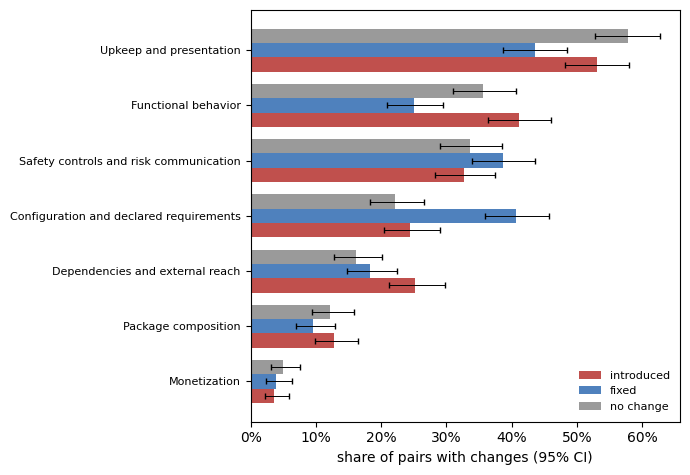

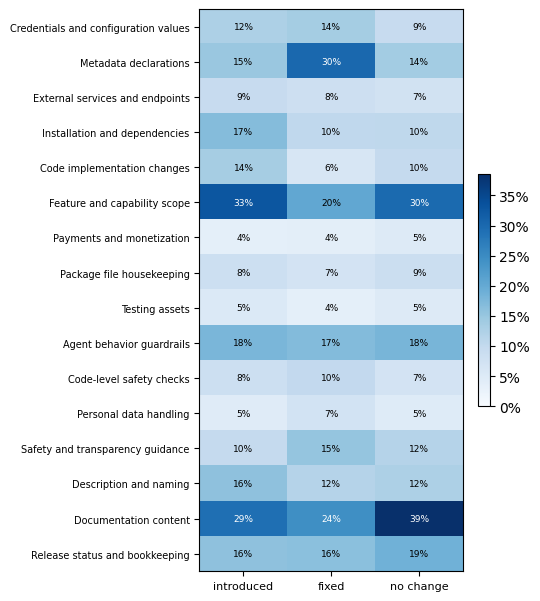

tables in results\rq1, figures in results\rq1\figs


In [14]:
# Figure 1: theme share by stratum with 95% CIs (Phase 2)
tl = theme_long[theme_long["stratum"].isin(STRATA)].copy()
order = theme_w.sort_values("all (weighted)")["all (weighted)"].index
colors = {"introduced": "#c0504d", "fixed": "#4f81bd", "no change": "#9a9a9a"}
fig, ax = plt.subplots(figsize=(7, 0.55 * len(order) + 1))
h = 0.26
for i, s in enumerate(STRATA):
    d = tl[tl["stratum"] == s].set_index("category").reindex(order)
    y = np.arange(len(order)) + (i - 1) * h
    ax.barh(y, d["share"], height=h, color=colors[s], label=s)
    ax.errorbar(d["share"], y, xerr=[d["share"] - d["ci_low"], d["ci_high"] - d["share"]],
                fmt="none", ecolor="k", lw=0.7, capsize=2)
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of pairs with changes (95% CI)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "p2_theme_by_stratum.png", dpi=200); plt.show()

# Figure 2: subtheme x stratum heatmap (Phase 2)
hm = sub_w.set_index("theme", append=True)[STRATA].sort_index(level=1)
fig, ax = plt.subplots(figsize=(5.5, 0.32 * len(hm) + 1))
im = ax.imshow(hm.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(STRATA))); ax.set_xticklabels(STRATA, fontsize=8)
ax.set_yticks(range(len(hm))); ax.set_yticklabels([s for s, _ in hm.index], fontsize=7)
for (r, c), v in np.ndenumerate(hm.values):
    ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=6.5,
            color="white" if v > hm.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig(FIGS / "p2_subtheme_heatmap.png", dpi=200); plt.show()
print(f"tables in {OUT}, figures in {FIGS}")